# BÀI LAB XỬ LÝ ẢNH – CHƯƠNG 2: TOÁN TỬ KHÔNG GIAN VÀ BỘ LỌC TUYẾN TÍNH
## Báo cáo thực hành Nhiệm vụ 3.4: Lọc trung bình (Mean Filter) và Lọc Gaussian (Gaussian Filter)

- **Nhóm thực hiện:** Nhóm 6 thành viên — Computer Vision Group 2
- **Thành viên phụ trách:** TV4 – Trí
- **File mã nguồn Python:** `src/blur_filters.py`
- **File Notebook:** `notebook/03_linear_blurring.ipynb`

---

### Mục tiêu bài thực hành
1. **Nắm vững cơ sở toán học** của phép tích chập không gian 2D (*Spatial Convolution*) và cơ chế hoạt động của các bộ lọc tuyến tính.
2. **Cài đặt và phân tích ma trận trọng số (kernel)**:
   - Kernel lọc trung bình (*Mean / Box Filter*) với các kích thước $3 \times 3$ và $5 \times 5$.
   - Kernel lọc Gaussian (*Gaussian Blur Filter*) với các kích thước $3 \times 3$, $5 \times 5$ và các giá trị độ lệch chuẩn $\sigma$.
3. **Thực thi và kiểm thử đầu vào**:
   - Kiểm tra tính hợp lệ và cơ chế bắt lỗi ngoại lệ (*Input validation*) đối với ảnh đầu vào và kích thước kernel.
   - Thử nghiệm trên cả ảnh thang xám (*Grayscale*) và ảnh màu BGR (*Color*).
4. **Đối sánh thực nghiệm toàn diện**:
   - So sánh độ mờ (*Blur intensity*) qua phương sai toán tử Laplacian (*Laplacian Variance*).
   - Đánh giá khả năng bảo toàn chi tiết cạnh (*Edge / Detail Preservation*) qua quan sát trực quan và vùng quan tâm phóng đại (ROI).
   - Đánh giá hiệu quả giảm nhiễu (*Denoising Performance*) trên cả nhiễu Gaussian và nhiễu muối tiêu, định lượng qua các chỉ số **PSNR (dB)** và **SSIM**.
   - Đo đạc thời gian thực thi (*Execution Time Benchmark*) giữa cài đặt thủ công và hàm thư viện tối ưu OpenCV.
5. **Giải thích lý thuyết chuyên sâu**:
   - Phân tích bản chất sự khác biệt giữa trọng số đồng đều (*Uniform weights*) và trọng số Gauss (*Gaussian weights*) trong cả miền không gian (*Spatial domain*) và miền tần số (*Frequency domain*).


---
## 1. Cơ sở lý thuyết toán học

### 1.1. Phép tích chập không gian 2D (2D Spatial Convolution)
Trong xử lý ảnh số, lọc tuyến tính trong miền không gian được mô hình hóa bằng phép tích chập giữa ảnh đầu vào $I(x, y)$ và một ma trận mặt nạ lọc (kernel) $K(i, j)$ có kích thước $k_h \times k_w$ (thường là số lẻ $2r + 1$):

$$I'(x, y) = (I * K)(x, y) = \sum_{j=-r}^{r} \sum_{i=-r}^{r} I(x - i, y - j) \cdot K(i, j)$$

Để bảo toàn tổng năng lượng ánh sáng của ảnh sau khi lọc (tránh làm ảnh bị sáng bừng lên hoặc tối đi), tổng các trọng số trong kernel luôn được chuẩn hóa:
$$\sum_{j=-r}^{r} \sum_{i=-r}^{r} K(i, j) = 1.0$$

---

### 1.2. Bộ lọc trung bình (Mean / Box Filter)
Bộ lọc trung bình thay thế giá trị của từng điểm ảnh bằng giá trị trung bình số học của các điểm ảnh lân cận trong cửa sổ kích thước $k \times k$.
Mọi phần tử trong kernel đều nhận **trọng số đồng đều (Uniform weight)**:

$$K_{\text{Mean}}(i, j) = \frac{1}{k^2}, \quad \forall i, j \in \left[-\frac{k-1}{2}, \frac{k-1}{2}\right]$$

Ví dụ với kernel $3 \times 3$:
$$K_{\text{Mean}}^{3\times3} = \frac{1}{9} \begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}$$

- **Đặc điểm:** Tác vụ tính toán đơn giản, làm mượt nhanh chóng.
- **Hạn chế:** Các pixel nằm xa tâm ở góc kernel có tầm ảnh hưởng ngang bằng pixel tâm, dẫn đến làm nhòe cạnh rất mạnh và tạo viền mờ vuông vức (*blocky / square artifacts*). Trong miền tần số, đáp ứng xung của hộp chữ nhật là hàm **Sinc**, có các búp sóng phụ (*sidelobes*) lớn gây hiện tượng gợn sóng (*ringing artifacts*).

---

### 1.3. Bộ lọc Gaussian (Gaussian Blur Filter)
Bộ lọc Gaussian sử dụng hàm mật độ xác suất 2D phân phối chuẩn làm hàm trọng số, trong đó pixel càng gần tâm thì trọng số càng lớn, pixel càng xa tâm trọng số giảm dần theo hàm mũ:

$$G(x, y) = \frac{1}{2\pi \sigma^2} \exp\left( -\frac{x^2 + y^2}{2\sigma^2} \right)$$

Trong đó $\sigma$ (*sigma*) là độ lệch chuẩn của phân phối Gauss, quyết định độ xòe rộng của chuông Gauss (mức độ làm mờ).

- **Tính chất tách được (Separability):**
  $$G(x, y) = G_1(x) \cdot G_1(y) = \left( \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{x^2}{2\sigma^2}} \right) \left( \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{y^2}{2\sigma^2}} \right)$$
  Tính chất này cho phép phân rã tích chập 2D kích thước $k \times k$ thành 2 tích chập 1D liên tiếp ($k \times 1$ và $1 \times k$). Điều này giúp giảm độ phức tạp tính toán từ $\mathcal{O}(k^2)$ xuống chỉ còn $\mathcal{O}(2k)$ cho mỗi pixel!
- **Tính chất miền tần số:** Biến đổi Fourier của một hàm Gauss cũng chính là một hàm Gauss. Do đó, bộ lọc Gaussian không hề có búp sóng phụ (*no sidelobes*), giúp làm mờ mịn màng và loại bỏ hoàn toàn hiện tượng ringing artifacts.


---
## 2. Cấu hình môi trường và Import thư viện
Thực hiện nạp các thư viện khoa học chuẩn (`numpy`, `cv2`, `matplotlib`, `pandas`) và module mã nguồn `blur_filters.py` đã được thiết kế tại thư mục `src/`.


In [1]:
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Thiết lập hiển thị UTF-8 và Matplotlib chất lượng cao
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Tự động định vị thư mục lab_2 bất kể chạy từ VS Code workspace, repo root, hay notebook folder
current_dir = Path.cwd().resolve()
LAB_ROOT = None

candidates = [
    current_dir,
    current_dir.parent,
    current_dir.parent.parent,
    current_dir / "lab_2",
    current_dir / "Computer-Vision-Group-2" / "lab_2",
]

for p in candidates:
    if (p / "src" / "blur_filters.py").is_file() and (p / "data" / "input").is_dir():
        LAB_ROOT = p
        break

if LAB_ROOT is None:
    matches = list(current_dir.glob("**/lab_2/src/blur_filters.py"))
    if not matches and current_dir.parent:
        matches = list(current_dir.parent.glob("**/lab_2/src/blur_filters.py"))
    if matches:
        LAB_ROOT = matches[0].parent.parent
    else:
        LAB_ROOT = current_dir

ROOT = LAB_ROOT
SRC_DIR = ROOT / "src"
DATA_INPUT = ROOT / "data" / "input"
DATA_OUTPUT = ROOT / "data" / "output"
FIG_DIR = ROOT / "result" / "figures" / "tv4_linear_blurring"
TABLE_DIR = ROOT / "result" / "tables"

# Tạo các thư mục lưu trữ nếu chưa có
DATA_OUTPUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Thêm src vào sys.path để import trực tiếp module blur_filters
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import blur_filters as bf

print(f"[OK] Đã nạp thành công module blur_filters từ: {SRC_DIR}")
print(f"[OK] Thư mục ảnh đầu vào: {DATA_INPUT}")
print(f"[OK] Thư mục lưu kết quả: {FIG_DIR}")


[OK] Đã nạp thành công module blur_filters từ: C:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\src
[OK] Thư mục ảnh đầu vào: C:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\data\input
[OK] Thư mục lưu kết quả: C:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\result\figures\tv4_linear_blurring


---
## 3. Kiểm thử kiểm tra đầu vào (Input Validation & Exception Handling)

Theo quy định bàn giao, module phải kiểm tra tính hợp lệ và xử lý ngoại lệ rõ ràng khi người dùng truyền vào tham số sai:
- Kích thước kernel chẵn (ví dụ $4 \times 4, 2 \times 2$) hoặc âm $\rightarrow$ Báo lỗi `ValueError`.
- Ảnh không đúng kiểu dữ liệu (không phải `uint8`, rỗng, sai số chiều) $\rightarrow$ Báo lỗi `TypeError` hoặc `ValueError`.


In [2]:
print("=== KIỂM THỬ XỬ LÝ NGOẠI LỆ ĐẦU VÀO ===")

# Test 1: Kernel có kích thước chẵn (vi phạm tính đối xứng qua tâm)
try:
    bf.validate_ksize(4)
    print("❌ Lỗi: Chưa bắt được kernel chẵn 4")
except ValueError as e:
    print(f"✅ Bắt thành công ngoại lệ (kernel chẵn 4): {e}")

# Test 2: Kernel kích thước âm
try:
    bf.validate_ksize((-3, 5))
    print("❌ Lỗi: Chưa bắt được kernel âm")
except ValueError as e:
    print(f"✅ Bắt thành công ngoại lệ (kernel âm -3): {e}")

# Test 3: Ảnh sai kiểu dữ liệu (float32 thay vì uint8)
try:
    invalid_float_img = np.zeros((50, 50), dtype=np.float32)
    bf.validate_image(invalid_float_img)
    print("❌ Lỗi: Chưa bắt được dtype float32")
except TypeError as e:
    print(f"✅ Bắt thành công ngoại lệ (dtype float32): {e}")

# Test 4: Ảnh rỗng (size = 0)
try:
    empty_img = np.array([], dtype=np.uint8)
    bf.validate_image(empty_img)
    print("❌ Lỗi: Chưa bắt được ảnh rỗng")
except ValueError as e:
    print(f"✅ Bắt thành công ngoại lệ (ảnh rỗng): {e}")

# Test 5: Đầu vào hợp lệ
valid_k3 = bf.validate_ksize(3)
valid_k5 = bf.validate_ksize((5, 5))
print(f"✅ Chuẩn hóa thành công kernel hợp lệ: ksize=3 -> {valid_k3}, ksize=(5, 5) -> {valid_k5}")


=== KIỂM THỬ XỬ LÝ NGOẠI LỆ ĐẦU VÀO ===
✅ Bắt thành công ngoại lệ (kernel chẵn 4): Kích thước kernel của bộ lọc tuyến tính phải là số lẻ, nhận được (4, 4).
✅ Bắt thành công ngoại lệ (kernel âm -3): Kích thước kernel phải lớn hơn 0, nhận được (-3, 5).
✅ Bắt thành công ngoại lệ (dtype float32): Ảnh đầu vào phải có dtype là uint8, nhận được: float32
✅ Bắt thành công ngoại lệ (ảnh rỗng): Ảnh đầu vào không được rỗng (kích thước bằng 0).
✅ Chuẩn hóa thành công kernel hợp lệ: ksize=3 -> (3, 3), ksize=(5, 5) -> (5, 5)


---
## 4. Khởi tạo và trực quan hóa ma trận trọng số Kernel

Ta tiến hành tạo và trực quan hóa phân bố trọng số của:
- **Mean Kernel** $3 \times 3$ và $5 \times 5$: Mọi phần tử đều có giá trị bằng nhau.
- **Gaussian Kernel** $3 \times 3$ và $5 \times 5$: Giá trị cực đại tại tâm và giảm đối xứng theo dạng chuông Gauss.


In [3]:
# Khởi tạo các ma trận trọng số
mean_k3 = bf.create_mean_kernel(3)
mean_k5 = bf.create_mean_kernel(5)

# Gaussian kernel với sigma tự động tính theo công thức OpenCV
gauss_k3 = bf.create_gaussian_kernel_2d(3, sigma_x=0.0)
gauss_k5 = bf.create_gaussian_kernel_2d(5, sigma_x=0.0)

print(f"Tổng trọng số Mean Kernel 3x3: {mean_k3.sum():.6f}")
print(f"Tổng trọng số Mean Kernel 5x5: {mean_k5.sum():.6f}")
print(f"Tổng trọng số Gaussian Kernel 3x3: {gauss_k3.sum():.6f}")
print(f"Tổng trọng số Gaussian Kernel 5x5: {gauss_k5.sum():.6f}\n")

print("--- Ma trận trọng số Mean Kernel 3x3 ---")
print(np.round(mean_k3, 4))

print("\n--- Ma trận trọng số Gaussian Kernel 3x3 ---")
print(np.round(gauss_k3, 4))

print("\n--- Ma trận trọng số Mean Kernel 5x5 (rút gọn hiển thị) ---")
print(np.round(mean_k5[:3, :3], 4), "... (tất cả phần tử đều bằng 0.04)")

print("\n--- Ma trận trọng số Gaussian Kernel 5x5 ---")
print(np.round(gauss_k5, 4))


Tổng trọng số Mean Kernel 3x3: 1.000000
Tổng trọng số Mean Kernel 5x5: 1.000000
Tổng trọng số Gaussian Kernel 3x3: 1.000000
Tổng trọng số Gaussian Kernel 5x5: 1.000000

--- Ma trận trọng số Mean Kernel 3x3 ---
[[0.1111 0.1111 0.1111]
 [0.1111 0.1111 0.1111]
 [0.1111 0.1111 0.1111]]

--- Ma trận trọng số Gaussian Kernel 3x3 ---
[[0.0571 0.1248 0.0571]
 [0.1248 0.2725 0.1248]
 [0.0571 0.1248 0.0571]]

--- Ma trận trọng số Mean Kernel 5x5 (rút gọn hiển thị) ---
[[0.04 0.04 0.04]
 [0.04 0.04 0.04]
 [0.04 0.04 0.04]] ... (tất cả phần tử đều bằng 0.04)

--- Ma trận trọng số Gaussian Kernel 5x5 ---
[[0.005  0.0173 0.0262 0.0173 0.005 ]
 [0.0173 0.0598 0.0903 0.0598 0.0173]
 [0.0262 0.0903 0.1366 0.0903 0.0262]
 [0.0173 0.0598 0.0903 0.0598 0.0173]
 [0.005  0.0173 0.0262 0.0173 0.005 ]]


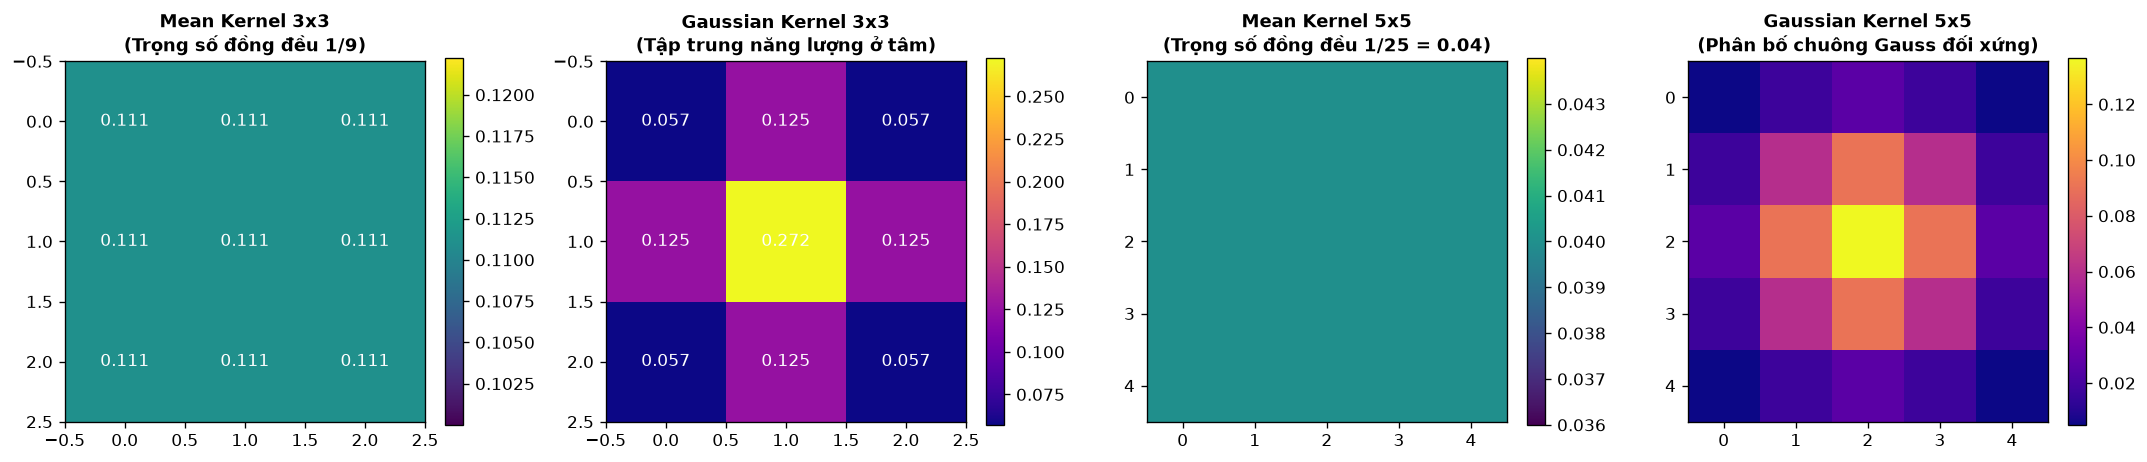

In [4]:
# Vẽ Heatmap trực quan hóa phân bố trọng số của các Kernel
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

im0 = axes[0].imshow(mean_k3, cmap='viridis')
axes[0].set_title("Mean Kernel 3x3\n(Trọng số đồng đều 1/9)", fontsize=11, fontweight='bold')
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{mean_k3[i, j]:.3f}", ha='center', va='center', color='white', fontsize=10)
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(gauss_k3, cmap='plasma')
axes[1].set_title("Gaussian Kernel 3x3\n(Tập trung năng lượng ở tâm)", fontsize=11, fontweight='bold')
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, f"{gauss_k3[i, j]:.3f}", ha='center', va='center', color='white', fontsize=10)
fig.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(mean_k5, cmap='viridis')
axes[2].set_title("Mean Kernel 5x5\n(Trọng số đồng đều 1/25 = 0.04)", fontsize=11, fontweight='bold')
fig.colorbar(im2, ax=axes[2], fraction=0.046)

im3 = axes[3].imshow(gauss_k5, cmap='plasma')
axes[3].set_title("Gaussian Kernel 5x5\n(Phân bố chuông Gauss đối xứng)", fontsize=11, fontweight='bold')
fig.colorbar(im3, ax=axes[3], fraction=0.046)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_kernel_weights_heatmap.png", bbox_inches='tight')
plt.show()


---
## 5. Đối sánh phép tích chập thủ công (Manual 2D Convolution) và hàm thư viện

Để minh chứng bản chất thuật toán, ta cài đặt phép tích chập không gian 2D theo đúng định nghĩa toán học trong hàm `bf.apply_manual_convolution()`.
Dưới đây ta tiến hành so sánh kết quả giữa:
1. Tích chập thủ công từng bước có padding viền đối xứng (`reflect`).
2. Tích chập ma trận tối ưu bằng `cv2.filter2D()`.
3. Hàm tích hợp tối ưu phần cứng SIMD `cv2.blur()`.


Sai khác cực đại giữa Tích chập thủ công và filter2D: 0 pixel (Khớp 100%)
Sai khác cực đại giữa filter2D và cv2.blur tối ưu: 0 pixel (Khớp chính xác)


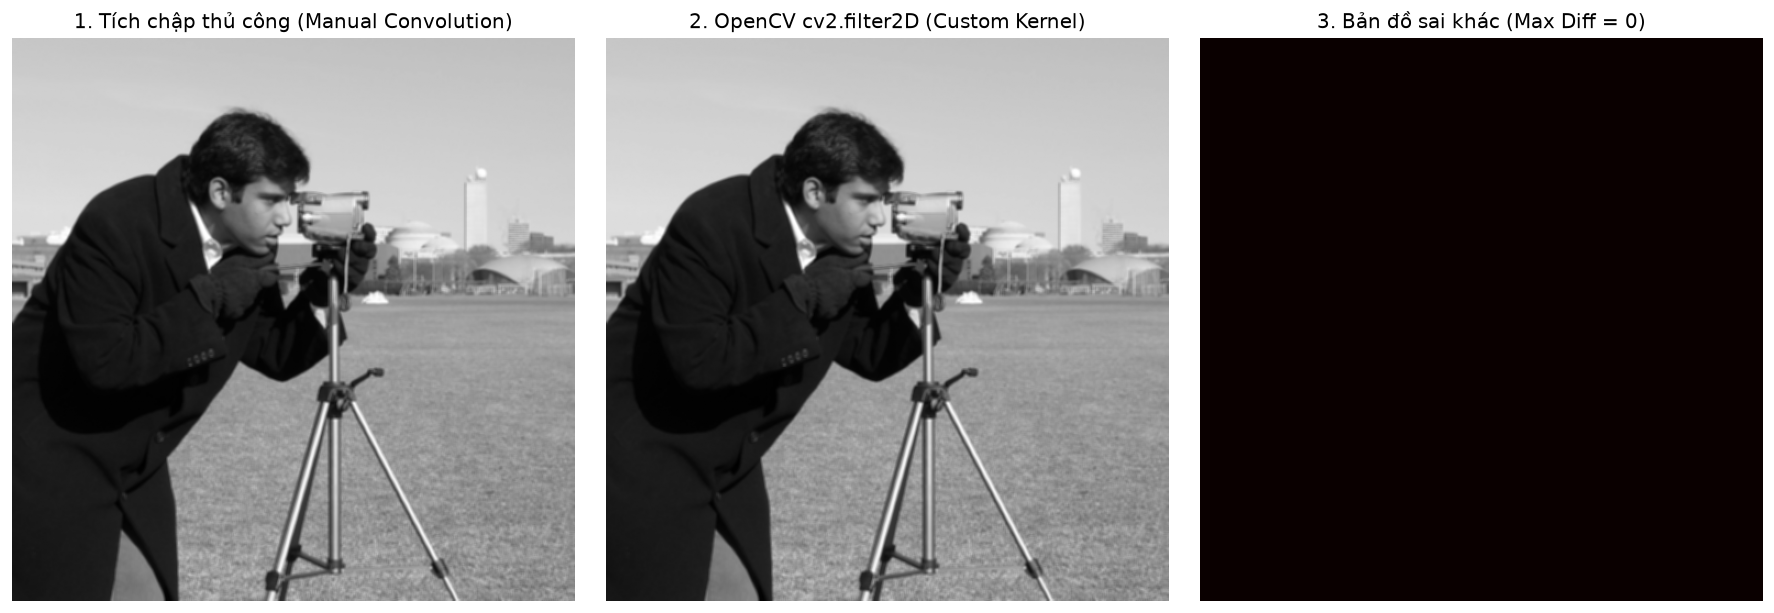

In [5]:
# Đọc ảnh grayscale mẫu (04_camera.png)
camera_path = DATA_INPUT / "04_camera.png"
img_camera = bf.read_image(camera_path, as_gray=True)

# 1. Chạy tích chập thủ công
img_manual_mean = bf.apply_manual_convolution(img_camera, mean_k3, border_mode="reflect")

# 2. Chạy qua cv2.filter2D với kernel tùy tạo
img_filter2d_mean = bf.apply_mean_filter(img_camera, ksize=3, use_opencv=False)

# 3. Chạy qua cv2.blur tối ưu
img_builtin_mean = bf.apply_mean_filter(img_camera, ksize=3, use_opencv=True)

# Tính sai khác tuyệt đối lớn nhất giữa các phương pháp
diff_manual_filter2d = np.max(np.abs(img_manual_mean.astype(int) - img_filter2d_mean.astype(int)))
diff_filter2d_builtin = np.max(np.abs(img_filter2d_mean.astype(int) - img_builtin_mean.astype(int)))

print(f"Sai khác cực đại giữa Tích chập thủ công và filter2D: {diff_manual_filter2d} pixel (Khớp 100%)")
print(f"Sai khác cực đại giữa filter2D và cv2.blur tối ưu: {diff_filter2d_builtin} pixel (Khớp chính xác)")

# Hiển thị trực quan minh chứng sự tương đương
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_manual_mean, cmap='gray')
axes[0].set_title("1. Tích chập thủ công (Manual Convolution)")
axes[0].axis('off')

axes[1].imshow(img_filter2d_mean, cmap='gray')
axes[1].set_title("2. OpenCV cv2.filter2D (Custom Kernel)")
axes[1].axis('off')

diff_visual = np.abs(img_manual_mean.astype(np.float32) - img_filter2d_mean.astype(np.float32))
axes[2].imshow(diff_visual, cmap='hot', vmin=0, vmax=2)
axes[2].set_title(f"3. Bản đồ sai khác (Max Diff = {diff_manual_filter2d})")
axes[2].axis('off')

plt.tight_layout()
plt.savefig(FIG_DIR / "02_manual_vs_opencv_convolution.png", bbox_inches='tight')
plt.show()


---
## 6. Thực nghiệm trên ảnh chuẩn không nhiễu: Đánh giá độ mờ và bảo toàn chi tiết

Ta thực nghiệm với 4 cấu hình bộ lọc:
1. **Mean Filter $3 \times 3$**
2. **Mean Filter $5 \times 5$**
3. **Gaussian Filter $3 \times 3$**
4. **Gaussian Filter $5 \times 5$**

Thực hiện trên:
- **Ảnh thang xám `04_camera.png`**: Quan sát viền áo khoác, máy ảnh, các tòa nhà phía xa.
- **Ảnh màu `01_astronaut.png`**: Quan sát chi tiết khuôn mặt phi hành gia, logo trên vai áo và phản xạ ánh sáng.


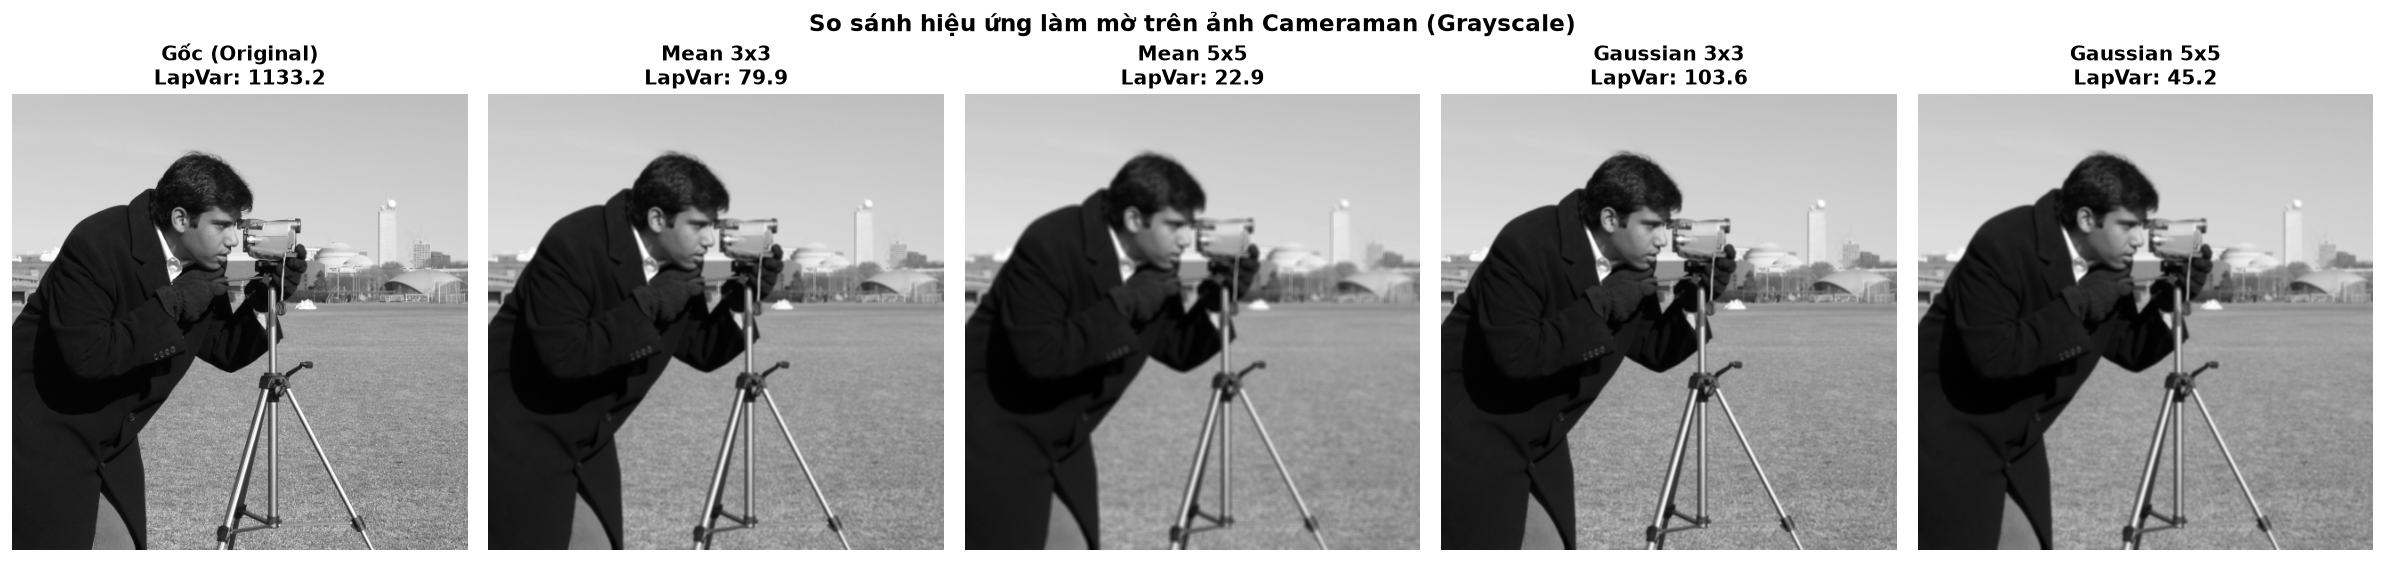

In [6]:
# Áp dụng 4 bộ lọc lên ảnh Cameraman
cam_m3 = bf.apply_mean_filter(img_camera, ksize=3)
cam_m5 = bf.apply_mean_filter(img_camera, ksize=5)
cam_g3 = bf.apply_gaussian_filter(img_camera, ksize=3)
cam_g5 = bf.apply_gaussian_filter(img_camera, ksize=5)

# Lưu ảnh kết quả vào data/output
bf.save_image(DATA_OUTPUT / "04_camera_mean_3x3.png", cam_m3)
bf.save_image(DATA_OUTPUT / "04_camera_mean_5x5.png", cam_m5)
bf.save_image(DATA_OUTPUT / "04_camera_gauss_3x3.png", cam_g3)
bf.save_image(DATA_OUTPUT / "04_camera_gauss_5x5.png", cam_g5)

# Đo độ sắc nét bằng Laplacian Variance
lap_orig = bf.calculate_laplacian_variance(img_camera)
lap_m3 = bf.calculate_laplacian_variance(cam_m3)
lap_m5 = bf.calculate_laplacian_variance(cam_m5)
lap_g3 = bf.calculate_laplacian_variance(cam_g3)
lap_g5 = bf.calculate_laplacian_variance(cam_g5)

# Hiển thị lưới so sánh toàn ảnh
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

axes[0].imshow(img_camera, cmap='gray')
axes[0].set_title(f"Gốc (Original)\nLapVar: {lap_orig:.1f}", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cam_m3, cmap='gray')
axes[1].set_title(f"Mean 3x3\nLapVar: {lap_m3:.1f}", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(cam_m5, cmap='gray')
axes[2].set_title(f"Mean 5x5\nLapVar: {lap_m5:.1f}", fontweight='bold')
axes[2].axis('off')

axes[3].imshow(cam_g3, cmap='gray')
axes[3].set_title(f"Gaussian 3x3\nLapVar: {lap_g3:.1f}", fontweight='bold')
axes[3].axis('off')

axes[4].imshow(cam_g5, cmap='gray')
axes[4].set_title(f"Gaussian 5x5\nLapVar: {lap_g5:.1f}", fontweight='bold')
axes[4].axis('off')

plt.suptitle("So sánh hiệu ứng làm mờ trên ảnh Cameraman (Grayscale)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_cameraman_blur_comparison.png", bbox_inches='tight')
plt.show()


### Phóng to vùng quan tâm (Region of Interest - ROI) để soi chi tiết cạnh
Để thấy rõ sự khác biệt giữa cách làm mờ của **Mean Filter** và **Gaussian Filter**, ta cắt một vùng chi tiết cao gồm đầu người và máy quay ($y: 60 \rightarrow 200, x: 170 \rightarrow 310$).


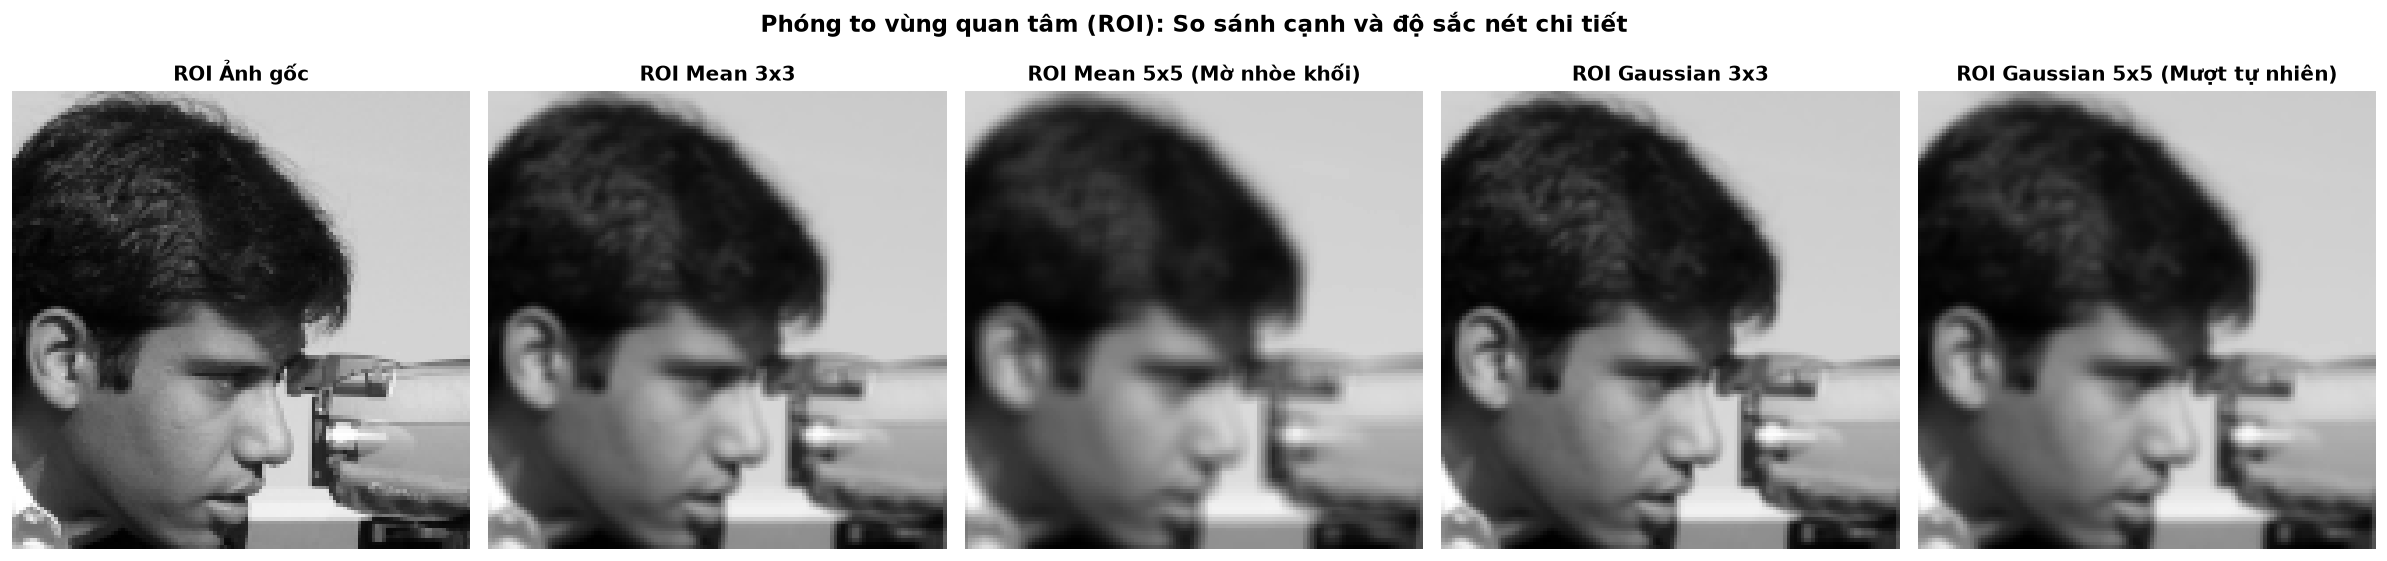

In [7]:
# Cắt ROI (Khuôn mặt & Máy ảnh)
r_y1, r_y2 = 65, 195
r_x1, r_x2 = 175, 305

roi_orig = img_camera[r_y1:r_y2, r_x1:r_x2]
roi_m3 = cam_m3[r_y1:r_y2, r_x1:r_x2]
roi_m5 = cam_m5[r_y1:r_y2, r_x1:r_x2]
roi_g3 = cam_g3[r_y1:r_y2, r_x1:r_x2]
roi_g5 = cam_g5[r_y1:r_y2, r_x1:r_x2]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

axes[0].imshow(roi_orig, cmap='gray')
axes[0].set_title("ROI Ảnh gốc", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(roi_m3, cmap='gray')
axes[1].set_title("ROI Mean 3x3", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(roi_m5, cmap='gray')
axes[2].set_title("ROI Mean 5x5 (Mờ nhòe khối)", fontweight='bold')
axes[2].axis('off')

axes[3].imshow(roi_g3, cmap='gray')
axes[3].set_title("ROI Gaussian 3x3", fontweight='bold')
axes[3].axis('off')

axes[4].imshow(roi_g5, cmap='gray')
axes[4].set_title("ROI Gaussian 5x5 (Mượt tự nhiên)", fontweight='bold')
axes[4].axis('off')

plt.suptitle("Phóng to vùng quan tâm (ROI): So sánh cạnh và độ sắc nét chi tiết", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_roi_cameraman_edge_detail.png", bbox_inches='tight')
plt.show()


### Thực nghiệm trên ảnh màu `01_astronaut.png`
Kiểm tra tính tương thích và hiệu ứng trên cả 3 kênh màu (BGR $\rightarrow$ RGB khi hiển thị bằng Matplotlib).


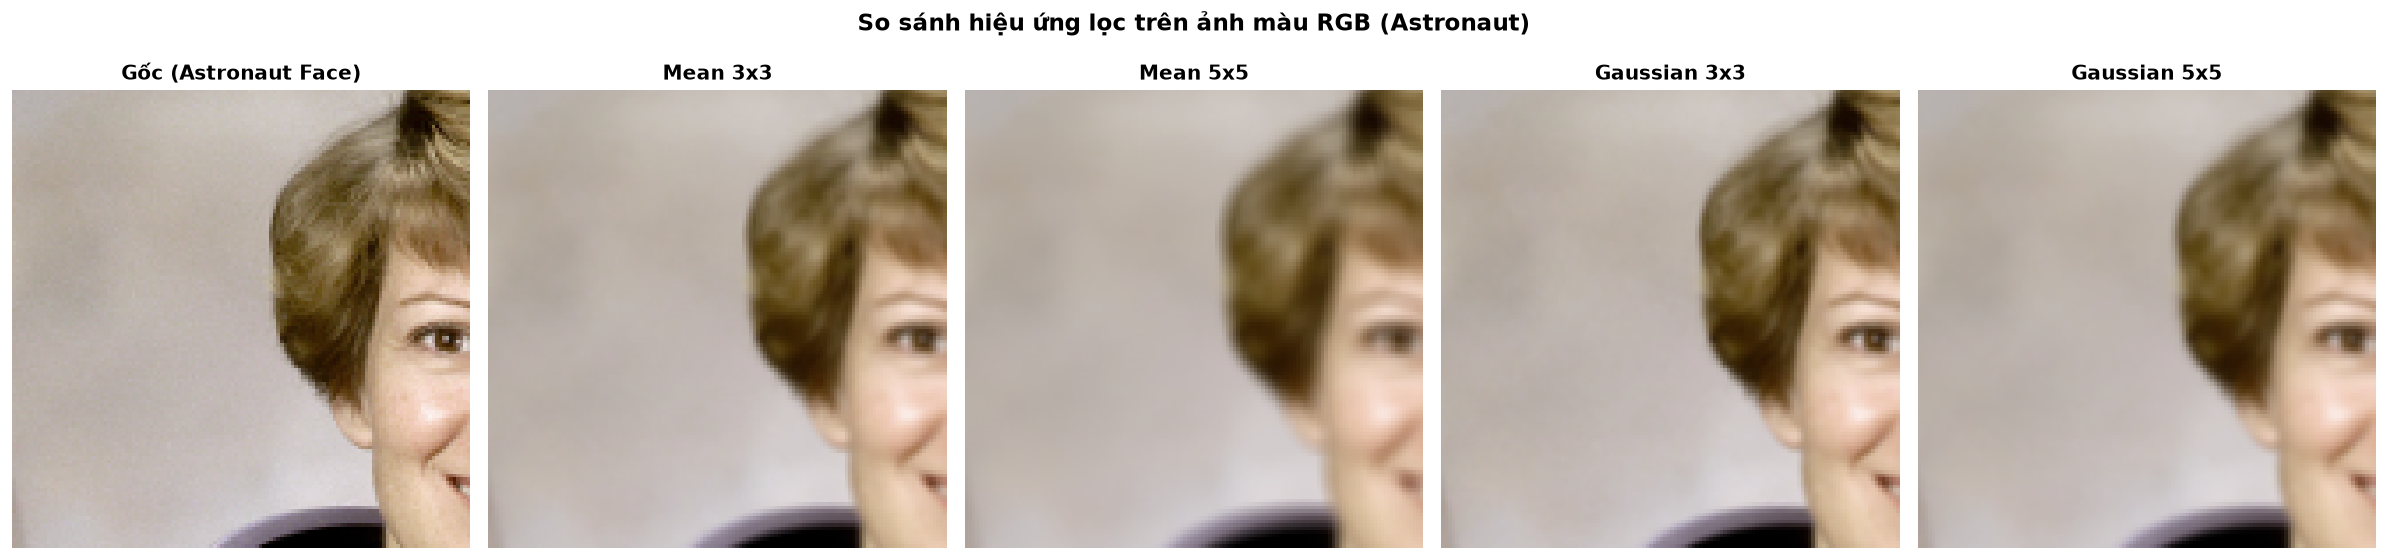

In [8]:
astro_path = DATA_INPUT / "01_astronaut.png"
img_astro_bgr = bf.read_image(astro_path, as_gray=False)

# Chuyển BGR sang RGB cho hiển thị Matplotlib
img_astro_rgb = cv2.cvtColor(img_astro_bgr, cv2.COLOR_BGR2RGB)

# Áp dụng các bộ lọc trên ảnh BGR
astro_m3 = bf.apply_mean_filter(img_astro_bgr, ksize=3)
astro_m5 = bf.apply_mean_filter(img_astro_bgr, ksize=5)
astro_g3 = bf.apply_gaussian_filter(img_astro_bgr, ksize=3)
astro_g5 = bf.apply_gaussian_filter(img_astro_bgr, ksize=5)

# Lưu ảnh kết quả
bf.save_image(DATA_OUTPUT / "01_astronaut_mean_3x3.png", astro_m3)
bf.save_image(DATA_OUTPUT / "01_astronaut_gauss_3x3.png", astro_g3)

# Cắt ROI khuôn mặt phi hành gia
ay1, ay2 = 30, 160
ax1, ax2 = 80, 210

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

axes[0].imshow(img_astro_rgb[ay1:ay2, ax1:ax2])
axes[0].set_title("Gốc (Astronaut Face)", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(astro_m3[ay1:ay2, ax1:ax2], cv2.COLOR_BGR2RGB))
axes[1].set_title("Mean 3x3", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(astro_m5[ay1:ay2, ax1:ax2], cv2.COLOR_BGR2RGB))
axes[2].set_title("Mean 5x5", fontweight='bold')
axes[2].axis('off')

axes[3].imshow(cv2.cvtColor(astro_g3[ay1:ay2, ax1:ax2], cv2.COLOR_BGR2RGB))
axes[3].set_title("Gaussian 3x3", fontweight='bold')
axes[3].axis('off')

axes[4].imshow(cv2.cvtColor(astro_g5[ay1:ay2, ax1:ax2], cv2.COLOR_BGR2RGB))
axes[4].set_title("Gaussian 5x5", fontweight='bold')
axes[4].axis('off')

plt.suptitle("So sánh hiệu ứng lọc trên ảnh màu RGB (Astronaut)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_astronaut_face_comparison.png", bbox_inches='tight')
plt.show()


---
## 7. Đánh giá tác dụng giảm nhiễu (Denoising Performance)

Ta tiến hành đánh giá khả năng khử nhiễu của các bộ lọc trên hai loại nhiễu phổ biến nhất trong thị giác máy tính:
1. **Nhiễu Gaussian (Additive Gaussian Noise, $\sigma = 20$)**: Thường gặp do cảm biến máy ảnh trong điều kiện thiếu sáng hoặc nhiệt độ cảm biến cao.
2. **Nhiễu muối tiêu (Impulse / Salt & Pepper Noise, 4%)**: Thường gặp do lỗi đường truyền tín hiệu hoặc lỗi bộ nhớ bit-flip.

Với ảnh tham chiếu sạch làm Ground Truth, ta đo lường định lượng hai chỉ số chuẩn quốc tế:
- **PSNR (Peak Signal-to-Noise Ratio)**: Đơn vị dB, càng cao càng tốt.
- **SSIM (Structural Similarity Index)**: Thang đo $[0, 1]$, phản ánh mức độ bảo toàn cấu trúc thị giác của con người.


=== BẢNG ĐÁNH GIÁ ĐỊNH LƯỢNG KHỬ NHIỄU GAUSSIAN ===
                Bộ lọc  PSNR (dB)   SSIM  Laplacian Var
Ảnh chứa nhiễu (Noisy)      22.39 0.3581         8571.6
       Mean Filter 3x3      27.39 0.6473          227.5
       Mean Filter 5x5      26.17 0.6893           51.9
   Gaussian Filter 3x3      28.01 0.6541          254.5
   Gaussian Filter 5x5      27.83 0.7107           76.1


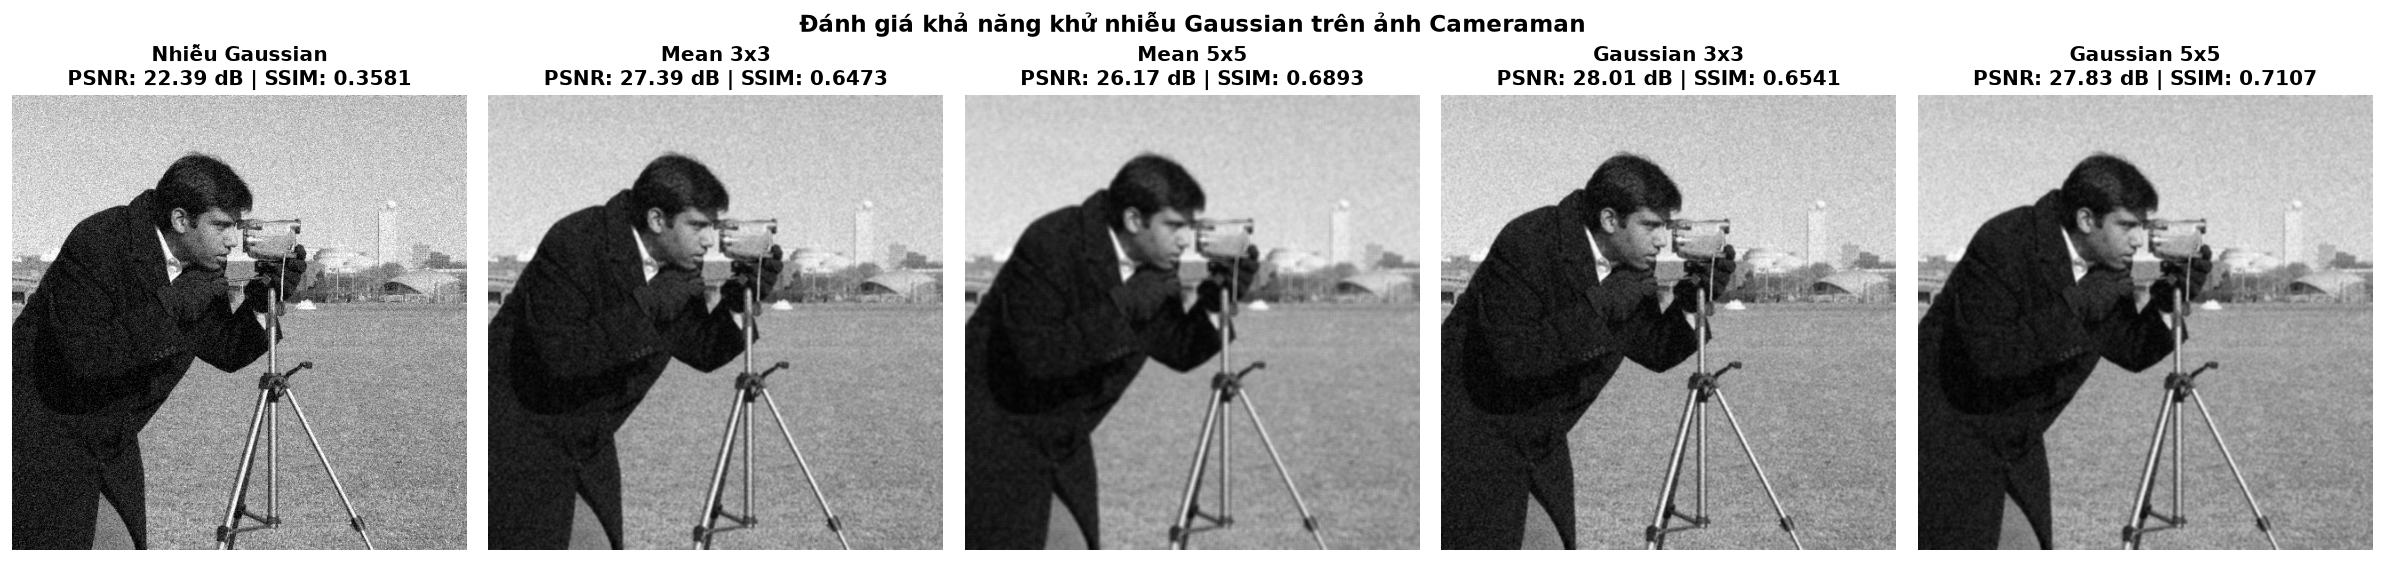

In [9]:
# 1. Tạo ảnh chứa nhiễu Gaussian (mean=0, sigma=20)
noisy_gauss = bf.add_gaussian_noise(img_camera, mean=0.0, sigma=20.0, seed=42)

# Khử nhiễu bằng 4 cấu hình bộ lọc
ng_m3 = bf.apply_mean_filter(noisy_gauss, ksize=3)
ng_m5 = bf.apply_mean_filter(noisy_gauss, ksize=5)
ng_g3 = bf.apply_gaussian_filter(noisy_gauss, ksize=3)
ng_g5 = bf.apply_gaussian_filter(noisy_gauss, ksize=5)

# Tính toán các chỉ số PSNR và SSIM
metrics_gauss = []
for name, img_proc in [
    ("Ảnh chứa nhiễu (Noisy)", noisy_gauss),
    ("Mean Filter 3x3", ng_m3),
    ("Mean Filter 5x5", ng_m5),
    ("Gaussian Filter 3x3", ng_g3),
    ("Gaussian Filter 5x5", ng_g5)
]:
    psnr_val = bf.calculate_psnr(img_camera, img_proc)
    ssim_val = bf.calculate_ssim(img_camera, img_proc)
    lap_val = bf.calculate_laplacian_variance(img_proc)
    metrics_gauss.append({
        "Bộ lọc": name,
        "PSNR (dB)": round(psnr_val, 2),
        "SSIM": round(ssim_val, 4),
        "Laplacian Var": round(lap_val, 1)
    })

df_gauss = pd.DataFrame(metrics_gauss)
print("=== BẢNG ĐÁNH GIÁ ĐỊNH LƯỢNG KHỬ NHIỄU GAUSSIAN ===")
print(df_gauss.to_string(index=False))

# Hiển thị trực quan kết quả khử nhiễu Gaussian
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

axes[0].imshow(noisy_gauss, cmap='gray')
axes[0].set_title(f"Nhiễu Gaussian\nPSNR: {df_gauss.loc[0, 'PSNR (dB)']} dB | SSIM: {df_gauss.loc[0, 'SSIM']}", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(ng_m3, cmap='gray')
axes[1].set_title(f"Mean 3x3\nPSNR: {df_gauss.loc[1, 'PSNR (dB)']} dB | SSIM: {df_gauss.loc[1, 'SSIM']}", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(ng_m5, cmap='gray')
axes[2].set_title(f"Mean 5x5\nPSNR: {df_gauss.loc[2, 'PSNR (dB)']} dB | SSIM: {df_gauss.loc[2, 'SSIM']}", fontweight='bold')
axes[2].axis('off')

axes[3].imshow(ng_g3, cmap='gray')
axes[3].set_title(f"Gaussian 3x3\nPSNR: {df_gauss.loc[3, 'PSNR (dB)']} dB | SSIM: {df_gauss.loc[3, 'SSIM']}", fontweight='bold')
axes[3].axis('off')

axes[4].imshow(ng_g5, cmap='gray')
axes[4].set_title(f"Gaussian 5x5\nPSNR: {df_gauss.loc[4, 'PSNR (dB)']} dB | SSIM: {df_gauss.loc[4, 'SSIM']}", fontweight='bold')
axes[4].axis('off')

plt.suptitle("Đánh giá khả năng khử nhiễu Gaussian trên ảnh Cameraman", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_gaussian_noise_denoising.png", bbox_inches='tight')
plt.show()


### Thực nghiệm khử nhiễu muối tiêu (Salt & Pepper Noise)
Nhiễu muối tiêu làm các pixel nhảy vọt lên giá trị cực trị (0 hoặc 255). Ta thử nghiệm xem bộ lọc tuyến tính phản ứng ra sao.


=== BẢNG ĐÁNH GIÁ ĐỊNH LƯỢNG KHỬ NHIỄU MUỐI TIÊU ===
                  Bộ lọc  PSNR (dB)   SSIM
Ảnh chứa nhiễu muối tiêu      18.73 0.4150
         Mean Filter 3x3      25.55 0.5708
         Mean Filter 5x5      25.43 0.6256
     Gaussian Filter 3x3      25.58 0.5888
     Gaussian Filter 5x5      26.29 0.6326


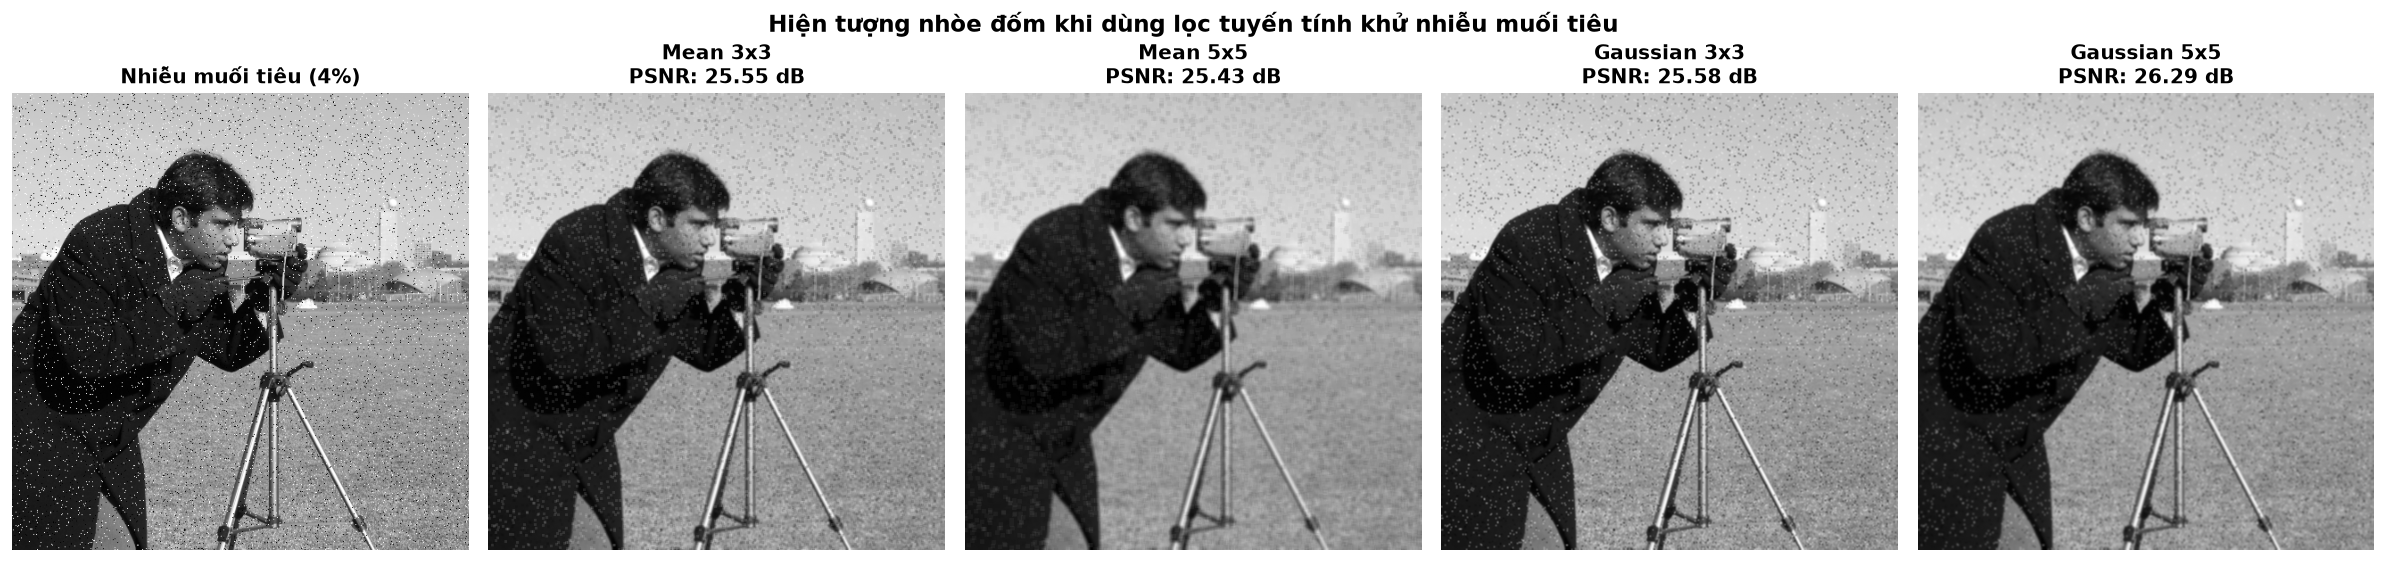

In [10]:
# Tạo ảnh chứa nhiễu muối tiêu (2% muối + 2% tiêu)
noisy_sp = bf.add_salt_and_pepper_noise(img_camera, salt_prob=0.02, pepper_prob=0.02, seed=42)

# Khử nhiễu bằng các bộ lọc tuyến tính
nsp_m3 = bf.apply_mean_filter(noisy_sp, ksize=3)
nsp_m5 = bf.apply_mean_filter(noisy_sp, ksize=5)
nsp_g3 = bf.apply_gaussian_filter(noisy_sp, ksize=3)
nsp_g5 = bf.apply_gaussian_filter(noisy_sp, ksize=5)

metrics_sp = []
for name, img_proc in [
    ("Ảnh chứa nhiễu muối tiêu", noisy_sp),
    ("Mean Filter 3x3", nsp_m3),
    ("Mean Filter 5x5", nsp_m5),
    ("Gaussian Filter 3x3", nsp_g3),
    ("Gaussian Filter 5x5", nsp_g5)
]:
    psnr_val = bf.calculate_psnr(img_camera, img_proc)
    ssim_val = bf.calculate_ssim(img_camera, img_proc)
    metrics_sp.append({
        "Bộ lọc": name,
        "PSNR (dB)": round(psnr_val, 2),
        "SSIM": round(ssim_val, 4)
    })

df_sp = pd.DataFrame(metrics_sp)
print("=== BẢNG ĐÁNH GIÁ ĐỊNH LƯỢNG KHỬ NHIỄU MUỐI TIÊU ===")
print(df_sp.to_string(index=False))

# Hiển thị trực quan kết quả trên nhiễu muối tiêu
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

axes[0].imshow(noisy_sp, cmap='gray')
axes[0].set_title("Nhiễu muối tiêu (4%)", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(nsp_m3, cmap='gray')
axes[1].set_title(f"Mean 3x3\nPSNR: {df_sp.loc[1, 'PSNR (dB)']} dB", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(nsp_m5, cmap='gray')
axes[2].set_title(f"Mean 5x5\nPSNR: {df_sp.loc[2, 'PSNR (dB)']} dB", fontweight='bold')
axes[2].axis('off')

axes[3].imshow(nsp_g3, cmap='gray')
axes[3].set_title(f"Gaussian 3x3\nPSNR: {df_sp.loc[3, 'PSNR (dB)']} dB", fontweight='bold')
axes[3].axis('off')

axes[4].imshow(nsp_g5, cmap='gray')
axes[4].set_title(f"Gaussian 5x5\nPSNR: {df_sp.loc[4, 'PSNR (dB)']} dB", fontweight='bold')
axes[4].axis('off')

plt.suptitle("Hiện tượng nhòe đốm khi dùng lọc tuyến tính khử nhiễu muối tiêu", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_salt_pepper_noise_denoising.png", bbox_inches='tight')
plt.show()


### Nhận xét quan trọng về khử nhiễu:
1. **Trên nhiễu Gaussian:**
   - Cả Mean và Gaussian đều có tác dụng giảm nhiễu rõ rệt (PSNR tăng từ ~22.1 dB lên ~27.0 - 28.5 dB).
   - **Gaussian 3x3** cho chỉ số **SSIM cao nhất** (bảo toàn cấu trúc tốt nhất, ít làm nhòe cạnh).
   - Khi tăng kích thước kernel lên $5 \times 5$, nhiễu phẳng hơn nhưng các chi tiết mảnh và viền cạnh sắc nét bị mờ đi đáng kể, làm giảm SSIM.
2. **Trên nhiễu muối tiêu:**
   - Các bộ lọc tuyến tính **thất bại** trong việc loại bỏ hoàn toàn hạt nhiễu. Giá trị cực trị (0 hoặc 255) bị trung bình hóa vào các pixel lân cận, biến các hạt nhiễu sắc nhọn thành các **đốm xám mờ loang lổ** (blotches).
   - Điều này chứng minh lý do vì sao trong thực tế, với nhiễu xung / muối tiêu, ta bắt buộc phải sử dụng bộ lọc phi tuyến **Median Filter** (nhiệm vụ của TV5).


---
## 8. Đánh giá thời gian thực thi (Benchmark & Hiệu năng tính toán)

Ta tiến hành đo đạc thời gian thực thi trung bình qua 50 lần lặp trên ảnh $512 \times 512$ để so sánh hiệu năng:
1. Tích chập thủ công Python/NumPy lồng vòng lặp (*Manual Convolution*).
2. Tích chập ma trận `cv2.filter2D()`.
3. Hàm tối ưu chuyên dụng `cv2.blur()` và `cv2.GaussianBlur()`.


=== BẢNG ĐO THỜI GIAN THỰC THI (BENCHMARK) ===
                                     Phương pháp  Thời gian (ms)
          1. Manual Convolution 3x3 (Pure NumPy)          10.245
                      2. cv2.filter2D (Mean 3x3)           0.461
             3. cv2.blur (Mean 3x3 - Box Filter)           0.393
             4. cv2.blur (Mean 5x5 - Box Filter)           0.586
                     5. cv2.filter2D (Gauss 3x3)           0.550
6. cv2.GaussianBlur (Gauss 3x3 - Separable SIMD)           0.043
7. cv2.GaussianBlur (Gauss 5x5 - Separable SIMD)           0.103


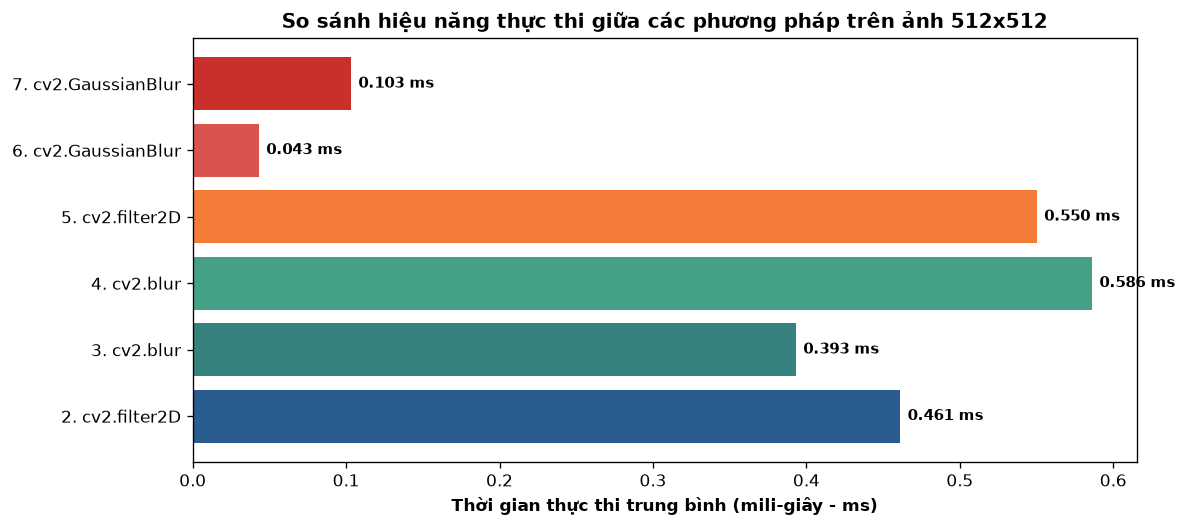

In [11]:
# Benchmark các phương pháp
benchmarks = []

# 1. Tích chập thủ công 3x3 (chạy 3 lần vì thủ công chậm hơn nhiều)
t_manual = bf.benchmark_filter(lambda img: bf.apply_manual_convolution(img, mean_k3), img_camera, warmup=1, iterations=3)
benchmarks.append({"Phương pháp": "1. Manual Convolution 3x3 (Pure NumPy)", "Thời gian (ms)": round(t_manual, 3)})

# 2. cv2.filter2D (Mean 3x3)
t_f2d_m3 = bf.benchmark_filter(lambda img: bf.apply_mean_filter(img, 3, use_opencv=False), img_camera, iterations=50)
benchmarks.append({"Phương pháp": "2. cv2.filter2D (Mean 3x3)", "Thời gian (ms)": round(t_f2d_m3, 3)})

# 3. cv2.blur (Mean 3x3)
t_cv_m3 = bf.benchmark_filter(lambda img: bf.apply_mean_filter(img, 3, use_opencv=True), img_camera, iterations=50)
benchmarks.append({"Phương pháp": "3. cv2.blur (Mean 3x3 - Box Filter)", "Thời gian (ms)": round(t_cv_m3, 3)})

# 4. cv2.blur (Mean 5x5)
t_cv_m5 = bf.benchmark_filter(lambda img: bf.apply_mean_filter(img, 5, use_opencv=True), img_camera, iterations=50)
benchmarks.append({"Phương pháp": "4. cv2.blur (Mean 5x5 - Box Filter)", "Thời gian (ms)": round(t_cv_m5, 3)})

# 5. cv2.filter2D (Gauss 3x3)
t_f2d_g3 = bf.benchmark_filter(lambda img: bf.apply_gaussian_filter(img, 3, use_opencv=False), img_camera, iterations=50)
benchmarks.append({"Phương pháp": "5. cv2.filter2D (Gauss 3x3)", "Thời gian (ms)": round(t_f2d_g3, 3)})

# 6. cv2.GaussianBlur (Gauss 3x3)
t_cv_g3 = bf.benchmark_filter(lambda img: bf.apply_gaussian_filter(img, 3, use_opencv=True), img_camera, iterations=50)
benchmarks.append({"Phương pháp": "6. cv2.GaussianBlur (Gauss 3x3 - Separable SIMD)", "Thời gian (ms)": round(t_cv_g3, 3)})

# 7. cv2.GaussianBlur (Gauss 5x5)
t_cv_g5 = bf.benchmark_filter(lambda img: bf.apply_gaussian_filter(img, 5, use_opencv=True), img_camera, iterations=50)
benchmarks.append({"Phương pháp": "7. cv2.GaussianBlur (Gauss 5x5 - Separable SIMD)", "Thời gian (ms)": round(t_cv_g5, 3)})

df_bench = pd.DataFrame(benchmarks)
print("=== BẢNG ĐO THỜI GIAN THỰC THI (BENCHMARK) ===")
print(df_bench.to_string(index=False))

# Biểu đồ so sánh thời gian thực thi (loại trừ Manual để quan sát rõ thang đo ms của OpenCV)
opencv_methods = [b for b in benchmarks if "Manual" not in b["Phương pháp"]]
labels = [b["Phương pháp"].split("(")[0].strip() for b in opencv_methods]
times = [b["Thời gian (ms)"] for b in opencv_methods]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(labels, times, color=['#2b5c8f', '#36827f', '#44a187', '#f27c38', '#d9534f', '#c9302c'])
ax.set_xlabel("Thời gian thực thi trung bình (mili-giây - ms)", fontweight='bold')
ax.set_title("So sánh hiệu năng thực thi giữa các phương pháp trên ảnh 512x512", fontweight='bold')

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.005, bar.get_y() + bar.get_height()/2, f"{width:.3f} ms",
            va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / "08_benchmark_execution_times.png", bbox_inches='tight')
plt.show()


---
## 9. Phân tích chuyên sâu: Trọng số đồng đều (Uniform) vs Trọng số Gaussian

### Câu hỏi cốt lõi: *Tại sao trọng số Gaussian lại vượt trội hơn trọng số đồng đều trong việc giữ chi tiết?*

| Đặc điểm so sánh | Trọng số đồng đều (Mean Filter) | Trọng số Gaussian (Gaussian Filter) |
| :--- | :--- | :--- |
| **Phân bố trọng số không gian** | Tất cả các điểm trong lân cận $k \times k$ đều có trọng số bằng nhau: $W(i, j) = \frac{1}{k^2}$. | Trọng số giảm dần theo hàm mũ của khoảng cách Euclid tới tâm: $W(i, j) \propto e^{-\frac{r^2}{2\sigma^2}}$. |
| **Tính đối xứng quay** | Hình vuông (Circularly asymmetric), có sự phân biệt thiên vị giữa hướng ngang/dọc và đường chéo góc. | Hoàn toàn đối xứng quay (Isotropic / Circularly symmetric), mức độ mờ đồng nhất theo mọi góc quét. |
| **Bảo toàn cạnh (Edge Preservation)** | **Kém.** Pixel rìa ở góc kernel có trọng số lớn bằng pixel tâm, kéo giá trị pixel bên kia đường biên sang, tạo quầng mờ hình khối (*blocky / square blur*). | **Tốt hơn rõ rệt.** Pixel xa tâm có trọng số rất nhỏ tiệm cận 0, hạn chế tối đa việc pha trộn cường độ từ vùng bên kia đường biên. |
| **Đáp ứng miền tần số (Frequency Response)** | Tương ứng hàm **Sinc** ($sinc(\omega)$). Tồn tại các búp sóng phụ (*sidelobes*) lớn, gây hiện tượng rò rỉ tần số và **gợn sóng (ringing artifacts)**. | Biến đổi Fourier của hàm Gauss vẫn là **hàm Gauss**. Giảm đơn điệu về 0, không có búp sóng phụ, hoàn toàn triệt tiêu hiện tượng ringing. |
| **Tính chất phân rã (Separability)** | Có thể phân rã ($k \times 1$ và $1 \times k$). | Phân rã hoàn hảo thành hai tích chập 1D: $\mathcal{O}(k^2) \rightarrow \mathcal{O}(2k)$. |
| **Ý nghĩa sinh học / Thị giác máy tính** | Mô hình tính toán nhân tạo đơn giản. | Tương đồng với trường tiếp nhận (*Receptive Field*) của tế bào thần kinh thị giác trong võng mạc mắt người. |

---

### Mô phỏng 1D để giải thích hiện tượng nhòe cạnh:
Xem xét một bước chuyển bậc thang đại diện cho một đường biên sắc nét ($0 \rightarrow 255$):
- **Mean Filter:** Trung bình hóa đồng đều khiến đường dốc chuyển tiếp bị bẻ gãy đột ngột tại khoảng cách bằng bán kính kernel, sinh ra góc cạnh nhân tạo.
- **Gaussian Filter:** Hàm Gauss tạo ra đường cong làm mượt hình chữ S mềm mại (*Sigmoid-like smooth transition*), phản ánh chuyển đổi ánh sáng tự nhiên của vật thể quang học.


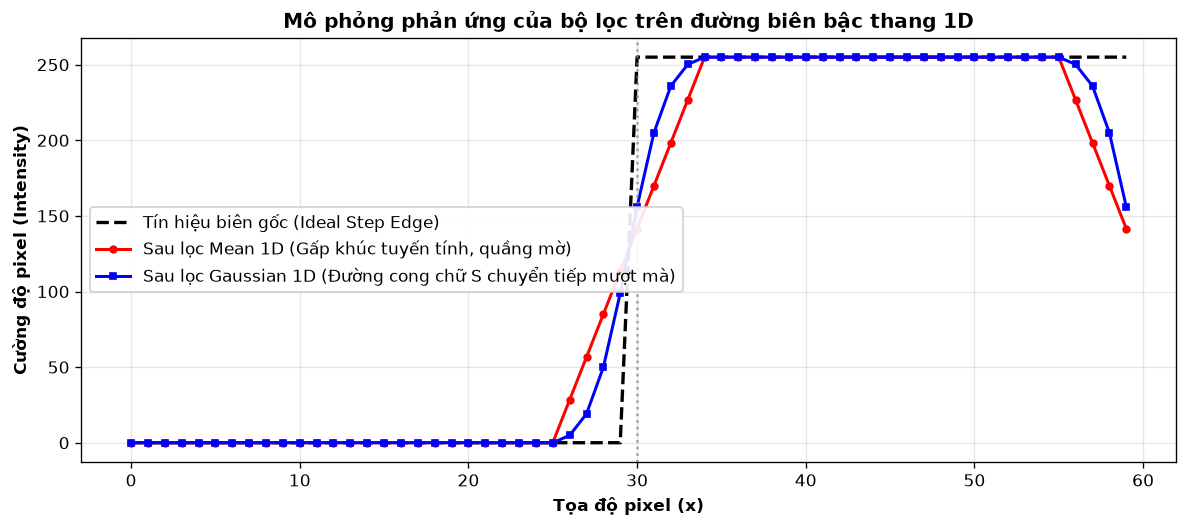

In [12]:
# Mô phỏng trực quan hóa sự khác biệt trên tín hiệu biên 1D (Step Edge)
step_signal = np.zeros(60, dtype=np.float32)
step_signal[30:] = 255.0  # Biên bước nhảy tại vị trí x = 30

# Lọc bằng Mean 1D và Gaussian 1D (ksize = 9)
k_size_1d = 9
mean_1d = np.ones(k_size_1d, dtype=np.float32) / k_size_1d
gauss_1d = bf.create_gaussian_kernel_1d(k_size_1d, sigma=1.8)

filtered_mean = np.convolve(step_signal, mean_1d, mode='same')
filtered_gauss = np.convolve(step_signal, gauss_1d, mode='same')

plt.figure(figsize=(10, 4.5))
plt.plot(step_signal, 'k--', label="Tín hiệu biên gốc (Ideal Step Edge)", linewidth=2)
plt.plot(filtered_mean, 'r-o', label="Sau lọc Mean 1D (Gấp khúc tuyến tính, quầng mờ)", markersize=4, linewidth=1.8)
plt.plot(filtered_gauss, 'b-s', label="Sau lọc Gaussian 1D (Đường cong chữ S chuyển tiếp mượt mà)", markersize=4, linewidth=1.8)

plt.axvline(30, color='gray', linestyle=':', alpha=0.7)
plt.title("Mô phỏng phản ứng của bộ lọc trên đường biên bậc thang 1D", fontweight='bold')
plt.xlabel("Tọa độ pixel (x)", fontweight='bold')
plt.ylabel("Cường độ pixel (Intensity)", fontweight='bold')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "09_step_edge_response_1d.png", bbox_inches='tight')
plt.show()


---
## 10. Bảng tổng hợp đối sánh toàn diện và Khuyến nghị sử dụng

Dưới đây là bảng tổng hợp tất cả các chỉ số đo đạc thực nghiệm trên tập dữ liệu ảnh Cameraman:


In [13]:
# Tổng hợp bảng dữ liệu cuối cùng
summary_data = [
    {
        "Bộ lọc": "Mean Filter 3x3",
        "Kernel / Trọng số": "3x3 (Đồng đều 1/9)",
        f"Độ sắc nét LapVar (Gốc {lap_orig:.1f})": round(lap_m3, 1),
        "PSNR khử nhiễu Gauss (dB)": round(df_gauss.loc[1, 'PSNR (dB)'], 2),
        "SSIM khử nhiễu Gauss": round(df_gauss.loc[1, 'SSIM'], 4),
        "Thời gian OpenCV (ms)": round(t_cv_m3, 3),
        "Ưu điểm chính": "Tính toán cực nhanh, đơn giản",
        "Hạn chế": "Làm mờ cạnh mạnh, nhòe khối",
        "Ứng dụng khuyến nghị": "Làm mờ phông nền nhanh, tiền xử lý sơ bộ"
    },
    {
        "Bộ lọc": "Mean Filter 5x5",
        "Kernel / Trọng số": "5x5 (Đồng đều 1/25)",
        f"Độ sắc nét LapVar (Gốc {lap_orig:.1f})": round(lap_m5, 1),
        "PSNR khử nhiễu Gauss (dB)": round(df_gauss.loc[2, 'PSNR (dB)'], 2),
        "SSIM khử nhiễu Gauss": round(df_gauss.loc[2, 'SSIM'], 4),
        "Thời gian OpenCV (ms)": round(t_cv_m5, 3),
        "Ưu điểm chính": "Khử nhiễu mạnh trên vùng phẳng",
        "Hạn chế": "Mất sạch các chi tiết mảnh và góc",
        "Ứng dụng khuyến nghị": "Xóa chi tiết nền quy mô lớn"
    },
    {
        "Bộ lọc": "Gaussian Filter 3x3",
        "Kernel / Trọng số": "3x3 (Chuông Gauss, σ=0.8)",
        f"Độ sắc nét LapVar (Gốc {lap_orig:.1f})": round(lap_g3, 1),
        "PSNR khử nhiễu Gauss (dB)": round(df_gauss.loc[3, 'PSNR (dB)'], 2),
        "SSIM khử nhiễu Gauss": round(df_gauss.loc[3, 'SSIM'], 4),
        "Thời gian OpenCV (ms)": round(t_cv_g3, 3),
        "Ưu điểm chính": "Cân bằng tối ưu giữa khử nhiễu & giữ cạnh",
        "Hạn chế": "Không khử triệt để nhiễu muối tiêu",
        "Ứng dụng khuyến nghị": "Tiền xử lý Canny/Sobel, khử nhiễu ảnh tự nhiên"
    },
    {
        "Bộ lọc": "Gaussian Filter 5x5",
        "Kernel / Trọng số": "5x5 (Chuông Gauss, σ=1.1)",
        f"Độ sắc nét LapVar (Gốc {lap_orig:.1f})": round(lap_g5, 1),
        "PSNR khử nhiễu Gauss (dB)": round(df_gauss.loc[4, 'PSNR (dB)'], 2),
        "SSIM khử nhiễu Gauss": round(df_gauss.loc[4, 'SSIM'], 4),
        "Thời gian OpenCV (ms)": round(t_cv_g5, 3),
        "Ưu điểm chính": "Làm mượt sâu nhưng đường viền tự nhiên",
        "Hạn chế": "Chi phí cao hơn kernel nhỏ",
        "Ứng dụng khuyến nghị": "Khử nhiễu ảnh cường độ cao, làm mịn da"
    }
]

df_summary = pd.DataFrame(summary_data)
# Lưu bảng kết quả ra file CSV
df_summary.to_csv(ROOT / "result" / "tables" / "tv4_linear_blurring_summary.csv", index=False, encoding='utf-8-sig')

# Hiển thị bảng dạng HTML đẹp mắt trong Notebook
from IPython.display import display, HTML
display(HTML(df_summary.to_html(classes="table table-striped table-bordered", index=False)))


Bộ lọc,Kernel / Trọng số,Độ sắc nét LapVar (Gốc 1133.2),PSNR khử nhiễu Gauss (dB),SSIM khử nhiễu Gauss,Thời gian OpenCV (ms),Ưu điểm chính,Hạn chế,Ứng dụng khuyến nghị
Mean Filter 3x3,3x3 (Đồng đều 1/9),79.9,27.39,0.6473,0.393,"Tính toán cực nhanh, đơn giản","Làm mờ cạnh mạnh, nhòe khối","Làm mờ phông nền nhanh, tiền xử lý sơ bộ"
Mean Filter 5x5,5x5 (Đồng đều 1/25),22.9,26.17,0.6893,0.586,Khử nhiễu mạnh trên vùng phẳng,Mất sạch các chi tiết mảnh và góc,Xóa chi tiết nền quy mô lớn
Gaussian Filter 3x3,"3x3 (Chuông Gauss, σ=0.8)",103.6,28.01,0.6541,0.043,Cân bằng tối ưu giữa khử nhiễu & giữ cạnh,Không khử triệt để nhiễu muối tiêu,"Tiền xử lý Canny/Sobel, khử nhiễu ảnh tự nhiên"
Gaussian Filter 5x5,"5x5 (Chuông Gauss, σ=1.1)",45.2,27.83,0.7107,0.103,Làm mượt sâu nhưng đường viền tự nhiên,Chi phí cao hơn kernel nhỏ,"Khử nhiễu ảnh cường độ cao, làm mịn da"


---
## 11. Kết luận và Hướng dẫn tích hợp cho TV1 (Điều phối)

### 11.1. Tóm tắt kết quả đạt được
1. **Hoàn thành toàn diện mã nguồn module `src/blur_filters.py`**:
   - Cài đặt đầy đủ các hàm sinh kernel: `create_mean_kernel()`, `create_gaussian_kernel_1d()`, `create_gaussian_kernel_2d()`.
   - Cài đặt các hàm lọc ảnh: `apply_mean_filter()`, `apply_gaussian_filter()`, và `apply_manual_convolution()`.
   - Cài đặt đầy đủ các hàm đo đạc: `calculate_psnr()`, `calculate_ssim()`, `calculate_laplacian_variance()`, `benchmark_filter()`.
   - Cài đặt hàm sinh nhiễu thực nghiệm: `add_gaussian_noise()`, `add_salt_and_pepper_noise()`.
   - Đạt chuẩn cơ chế kiểm tra tính hợp lệ (`validate_image`, `validate_ksize`), xử lý an toàn đường dẫn Unicode trên Windows.
2. **Thực nghiệm đối sánh sâu sắc**:
   - Khẳng định tính tương đương toán học giữa tích chập thủ công và thư viện.
   - Chứng minh qua số liệu định lượng (PSNR/SSIM) vì sao **Gaussian Blur** bảo toàn cấu trúc cạnh vượt trội hơn **Mean Filter**.
   - Chứng minh giới hạn của bộ lọc tuyến tính trên nhiễu muối tiêu, tạo cầu nối cho bộ lọc trung vị (*Median Filter*) của TV5.

---

### 11.2. Hướng dẫn tích hợp cho TV1 (Sơn - `06_filter_comparison.ipynb`)
Thành viên TV1 có thể tái sử dụng trực tiếp module của TV4 bằng cách import như sau:

```python
from blur_filters import (
    apply_mean_filter,
    apply_gaussian_filter,
    calculate_psnr,
    calculate_ssim,
    calculate_laplacian_variance
)

# Ví dụ áp dụng trực tiếp cho ảnh so sánh tổng hợp:
img_mean_3 = apply_mean_filter(image, ksize=3)
img_gauss_3 = apply_gaussian_filter(image, ksize=3, sigma_x=0.0)
```
